# **Importar librerias**



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# **Visualización y análisis de datos**

## Parte 1
Leer el dataset magic04.data usando la función pd.read_csv(). Se debe usar los siguientes nombres
para las columnas:
['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long',
'fM3Trans', 'fAlpha', 'fDist', 'class']

In [ ]:
data = 'magic04.data'
column_names = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
magic04_df = pd.read_csv(data, names=column_names)
print("DataFrame de magic04.data con los nombres de las columnas agregados:")
print(magic04_df)

DataFrame de magic04.data con los nombres de las columnas agregados:
        fLength    fWidth   fSize   fConc  fConc1     fAsym   fM3Long  \
0       28.7967   16.0021  2.6449  0.3918  0.1982   27.7004   22.0110   
1       31.6036   11.7235  2.5185  0.5303  0.3773   26.2722   23.8238   
2      162.0520  136.0310  4.0612  0.0374  0.0187  116.7410  -64.8580   
3       23.8172    9.5728  2.3385  0.6147  0.3922   27.2107   -6.4633   
4       75.1362   30.9205  3.1611  0.3168  0.1832   -5.5277   28.5525   
...         ...       ...     ...     ...     ...       ...       ...   
19015   21.3846   10.9170  2.6161  0.5857  0.3934   15.2618   11.5245   
19016   28.9452    6.7020  2.2672  0.5351  0.2784   37.0816   13.1853   
19017   75.4455   47.5305  3.4483  0.1417  0.0549   -9.3561   41.0562   
19018  120.5135   76.9018  3.9939  0.0944  0.0683    5.8043  -93.5224   
19019  187.1814   53.0014  3.2093  0.2876  0.1539 -167.3125 -168.4558   

       fM3Trans   fAlpha     fDist class  
0       -8.

In [ ]:
features = magic04_df.drop('class', axis=1)
scaler = MinMaxScaler()
normalized_features = scaler.fit_transform(features)
normalized_df = pd.DataFrame(normalized_features, columns=features.columns)
normalized_df['class'] = magic04_df['class']

print("DataFrame después de la normalización:")
print(normalized_df.head)

DataFrame después de la normalización:
<bound method NDFrame.head of         fLength    fWidth     fSize     fConc    fConc1     fAsym   fM3Long  \
0      0.074306  0.062415  0.208043  0.430390  0.293229  0.470032  0.620576   
1      0.082815  0.045727  0.170668  0.587794  0.558601  0.468649  0.623756   
2      0.478241  0.530579  0.626818  0.027617  0.027263  0.556215  0.468201   
3      0.059212  0.037338  0.117445  0.683714  0.580679  0.469558  0.570630   
4      0.214774  0.120603  0.360674  0.345153  0.271003  0.437870  0.632050   
...         ...       ...       ...       ...       ...       ...       ...   
19015  0.051838  0.042581  0.199527  0.650756  0.582457  0.457992  0.602182   
19016  0.074757  0.026141  0.096363  0.593249  0.412061  0.479112  0.605095   
19017  0.215712  0.185389  0.445594  0.146153  0.080901  0.434164  0.653983   
19018  0.352326  0.299950  0.606919  0.092397  0.100756  0.448838  0.417922   
19019  0.554415  0.206728  0.374926  0.311967  0.227589  0.281

## Parte 2
Separar los datos en dos subconjuntos, uno con los datos de la clase positiva (hadrón) y otro con los
de la clase negativa (no-hadrón).

In [ ]:
hadron_df = normalized_df[normalized_df['class'] == 'h']
gamma_df = normalized_df[normalized_df['class'] == 'g']
print("Subconjunto de la clase hadrón:")
print(hadron_df)
print("-----------------------------------------------")
print("Subconjunto de la clase gamma primarios:")
print(gamma_df)

Subconjunto de la clase hadrón:
        fLength    fWidth     fSize     fConc    fConc1     fAsym   fM3Long  \
12332  0.271057  0.147995  0.356032  0.176043  0.149355  0.494768  0.738179   
12333  0.296208  0.085816  0.406505  0.106035  0.106831  0.390870  0.657489   
12334  0.290985  0.085335  0.345565  0.339698  0.213809  0.396583  0.683098   
12335  0.264850  0.073442  0.227203  0.483578  0.506297  0.392227  0.410353   
12336  0.102263  0.049432  0.275991  0.449256  0.285227  0.393389  0.596608   
...         ...       ...       ...       ...       ...       ...       ...   
19015  0.051838  0.042581  0.199527  0.650756  0.582457  0.457992  0.602182   
19016  0.074757  0.026141  0.096363  0.593249  0.412061  0.479112  0.605095   
19017  0.215712  0.185389  0.445594  0.146153  0.080901  0.434164  0.653983   
19018  0.352326  0.299950  0.606919  0.092397  0.100756  0.448838  0.417922   
19019  0.554415  0.206728  0.374926  0.311967  0.227589  0.281277  0.286483   

       fM3Trans    

## Parte 3
Para cada característica, generar histogramas para los datos de la clase negativa y los de la clase
positiva. Para cada característica, ambos histogramas deben dibujarse usando un mismo gráfico. Para
esto, se debe usar plt.hist() con alpha=0.5. Los histogramas deben estar normalizados. Elija
un número de bins (particiones) que le parezca apropiado (investigue acerca de esto).

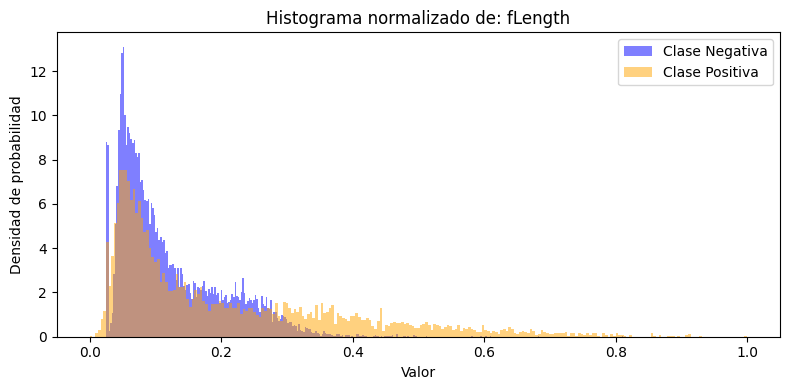

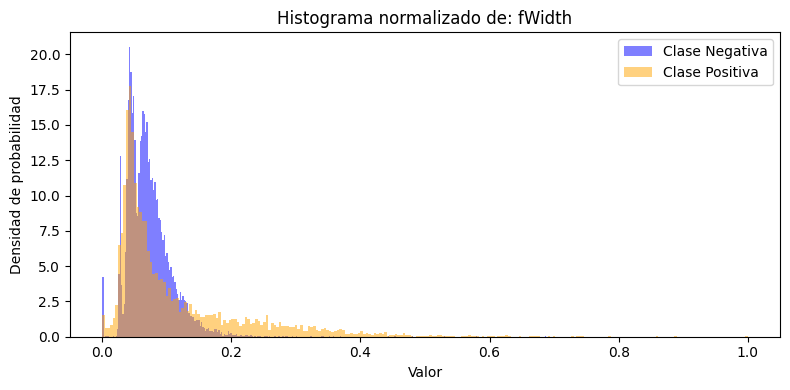

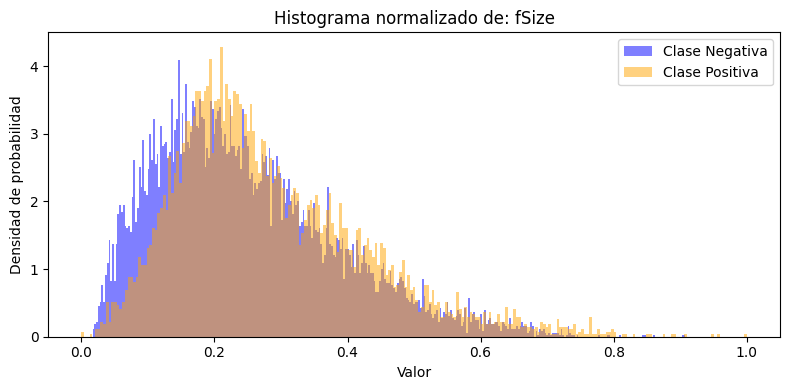

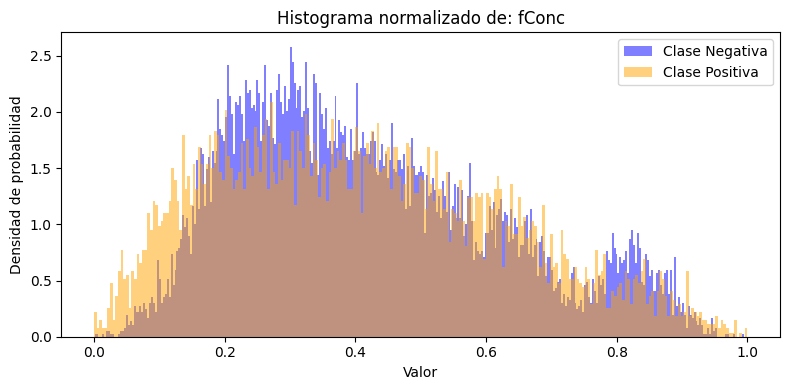

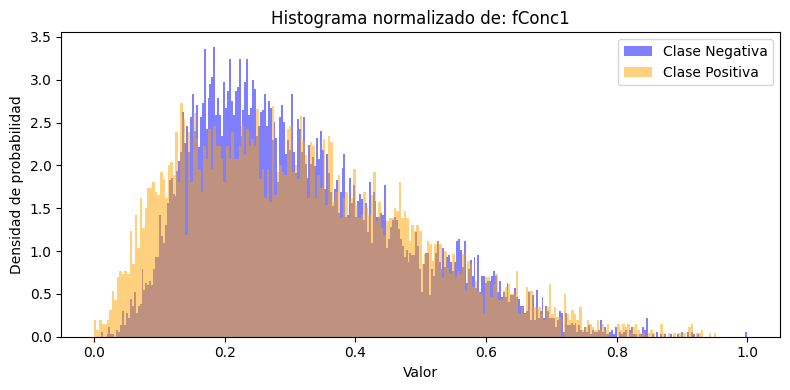

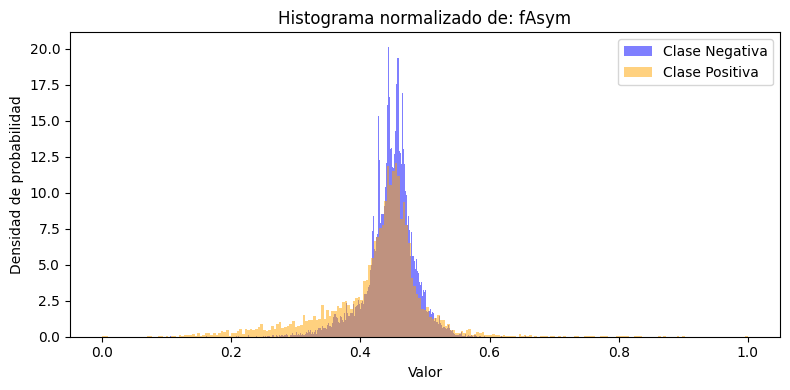

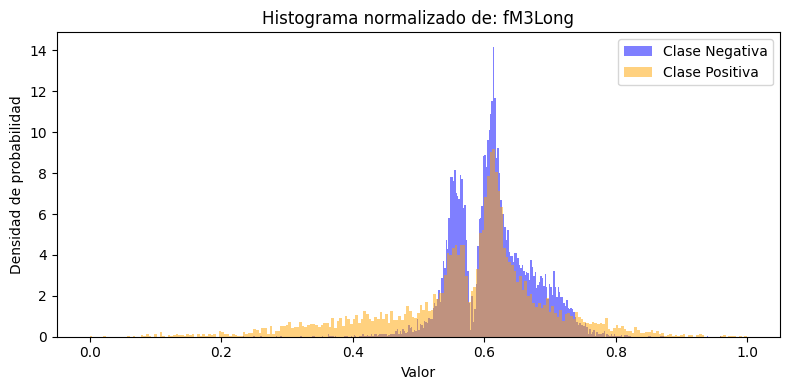

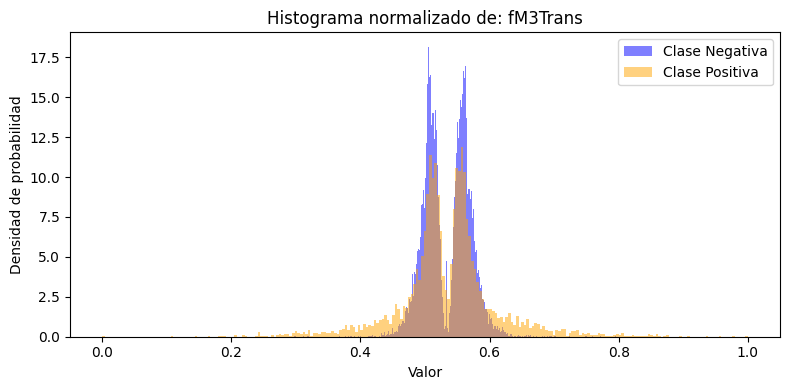

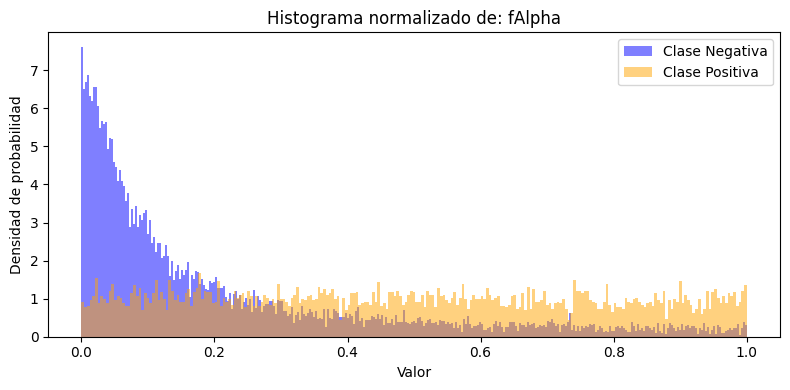

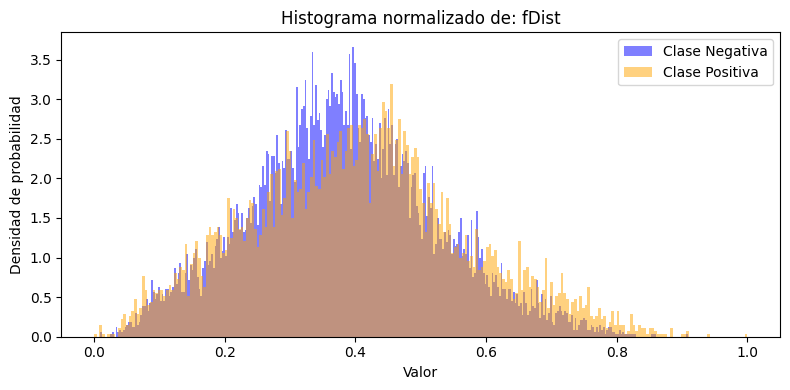

In [ ]:
# Particiones
bins_gamma = int(3 * np.sqrt(len(gamma_df)))
bins_hadron = int(3 * np.sqrt(len(hadron_df)))
# Histogramas
num_features = len(column_names[0:10])
for i, feature in enumerate(column_names[0:10]):
    fig, axs = plt.subplots(figsize=(8, 4))
    axs.hist(gamma_df[feature], bins=bins_gamma, density=True, alpha=0.5, color='blue', label='Clase Negativa')
    axs.hist(hadron_df[feature], bins=bins_hadron, density=True, alpha=0.5, color='orange', label='Clase Positiva')
    axs.set_xlabel('Valor')
    axs.set_ylabel('Densidad de probabilidad')
    axs.set_title(f'Histograma normalizado de: {feature}')
    axs.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

## Parte 4
Calcular y graficar la matriz de correlación de las características, considerando el valor absoluto de las
correlaciones. Incluir en este análisis la clase, como si fuera una característica extra (usar 0 para nohadron o 1 para hadrón). Se debe usar como base la función de correlación existente en pandas. Para
graficar se debe usar la función sns.heatmap( ) de seaborn.

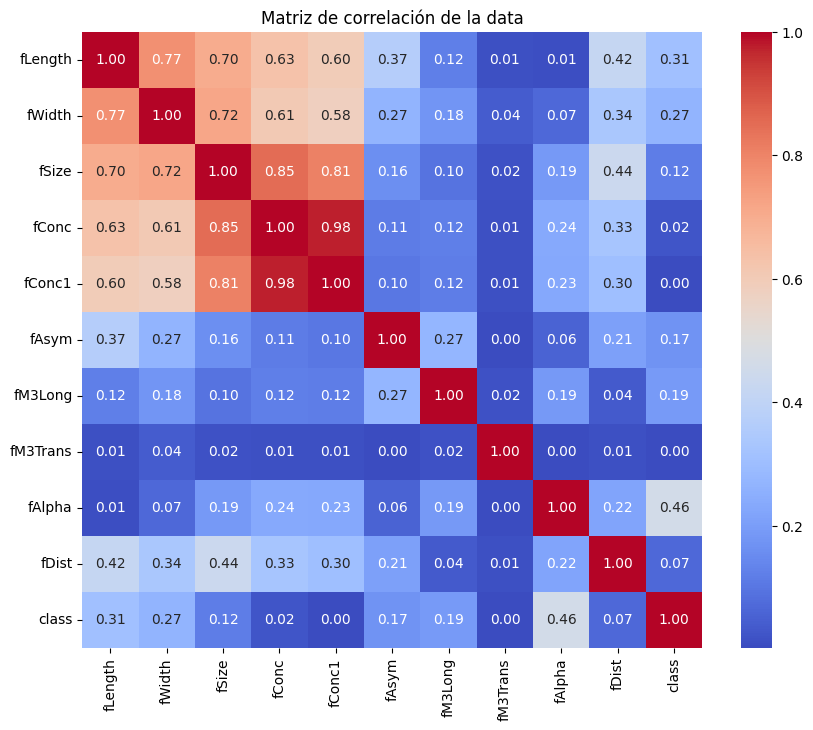

In [ ]:
normalized_df['class'] = normalized_df['class'].replace({'g': 0, 'h': 1})
correlation_matrix = normalized_df.corr().abs()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlación de la data')
plt.show()

## Parte 5
Indicar por orden cuáles son las características más correlacionadas con la clase.

In [ ]:
class_correlations = correlation_matrix['class']
class_correlations_sorted = class_correlations.sort_values(ascending=False)
class_correlations_sorted = class_correlations_sorted.drop('class')
top_correlations = class_correlations_sorted
print('Data frame con las caracteristicas más correlacionadas con la clase:')
print(top_correlations)
print('---------------------------------------------------------------')
print('Las caracteristicas más correlacionadas con la clase:')
for i, name in enumerate(top_correlations.index.values, start=1):
  print(f'{i}.- {name}')

Data frame con las caracteristicas más correlacionadas con la clase:
fAlpha      0.460979
fLength     0.307572
fWidth      0.265596
fM3Long     0.193409
fAsym       0.173587
fSize       0.117795
fDist       0.065203
fConc       0.024615
fConc1      0.004797
fM3Trans    0.003837
Name: class, dtype: float64
---------------------------------------------------------------
Las caracteristicas más correlacionadas con la clase:
1.- fAlpha
2.- fLength
3.- fWidth
4.- fM3Long
5.- fAsym
6.- fSize
7.- fDist
8.- fConc
9.- fConc1
10.- fM3Trans


## Parte 6
Indicar por orden cuáles son los 3 pares de características más correlacionadas entre sí. Averigüe
sobre unstack() y sort_values().

In [ ]:
mask = pd.DataFrame(False, index=correlation_matrix.index, columns=correlation_matrix.columns)
for i in range(len(correlation_matrix.columns)):
  for j in range(i+1, len(correlation_matrix.columns)):
    value = correlation_matrix.iloc[i, j]
    if value not in correlation_matrix.values[:i, j]:
      mask.iloc[i, j] = True
correlation_matrix_unique_values = correlation_matrix.mask(~mask)
correlation_pairs_sorted = correlation_matrix_unique_values.unstack().sort_values(ascending=False).dropna()
top_correlation_pairs = correlation_pairs_sorted[correlation_pairs_sorted !=1].head(3)
print('Data frame con las primeras tres caracteristicas más correlacionadas entre sí:')
print(top_correlation_pairs)
print('---------------------------------------------------------------')
print('Primeras tres caracteristicas más correlacionadas entre sí:')
for i, (pair, correlation) in enumerate(top_correlation_pairs.items(), start=1):
  feature1, feature2 = pair
  print(f'{i}.- {feature1} y {feature2}, con una correlación de {correlation}')

Data frame con las primeras tres caracteristicas más correlacionadas entre sí:
fConc1  fConc    0.976412
fConc   fSize    0.850850
fConc1  fSize    0.808835
dtype: float64
---------------------------------------------------------------
Primeras tres caracteristicas más correlacionadas entre sí:
1.- fConc1 y fConc, con una correlación de 0.9764118508094626
2.- fConc y fSize, con una correlación de 0.8508497973208063
3.- fConc1 y fSize, con una correlación de 0.8088350117321293


## Parte 7
Graficar las dos características más correlacionadas en un scatter plot (gráfico de dispersión)

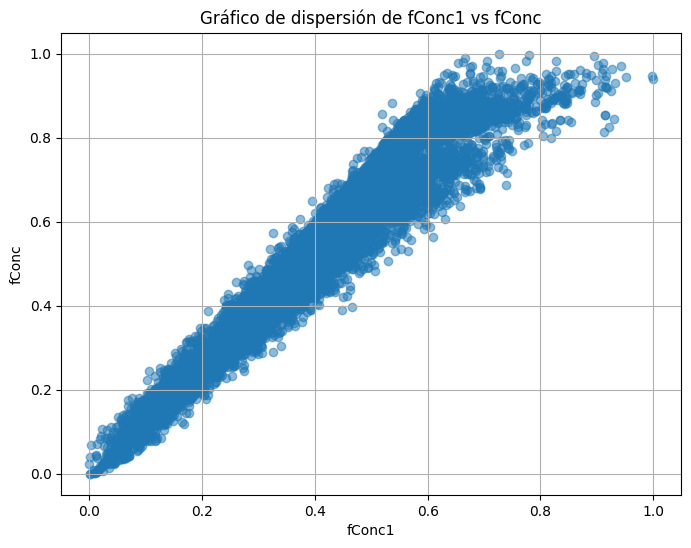

In [ ]:
feature1, feature2 = top_correlation_pairs.index[0]
feature1_data = normalized_df[feature1]
feature2_data = normalized_df[feature2]

plt.figure(figsize=(8,6))
plt.scatter(feature1_data, feature2_data, alpha=0.5)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title(f'Gráfico de dispersión de {feature1} vs {feature2}')
plt.grid(True)
plt.show()

## Parte 8
Indicar por orden cuáles son los 3 pares de características menos correlacionadas entre sí

In [ ]:
last_correlation_pairs = correlation_pairs_sorted[(correlation_pairs_sorted !=1)].sort_values(ascending=True).head(3)
print('Data frame con las ultimas tres caracteristicas más correlacionadas entre sí:')
print(last_correlation_pairs)
print('---------------------------------------------------------------')
print('Ultimas tres caracteristicas más correlacionadas entre sí:')
for i, (pair, correlation) in enumerate(last_correlation_pairs.items(), start=1):
  feature1, feature2 = pair
  print(f'{i}.- {feature1} y {feature2}, con una correlación de {correlation}')

Data frame con las ultimas tres caracteristicas más correlacionadas entre sí:
fM3Trans  fAsym       0.002553
class     fM3Trans    0.003837
fAlpha    fM3Trans    0.004659
dtype: float64
---------------------------------------------------------------
Ultimas tres caracteristicas más correlacionadas entre sí:
1.- fM3Trans y fAsym, con una correlación de 0.002552837319858875
2.- class y fM3Trans, con una correlación de 0.0038371980687589265
3.- fAlpha y fM3Trans, con una correlación de 0.004659125870349372


## Parte 9
Graficar las dos características menos correlacionadas en un scatter plot. Compare el gráfico obtenido
con el del punto 7.

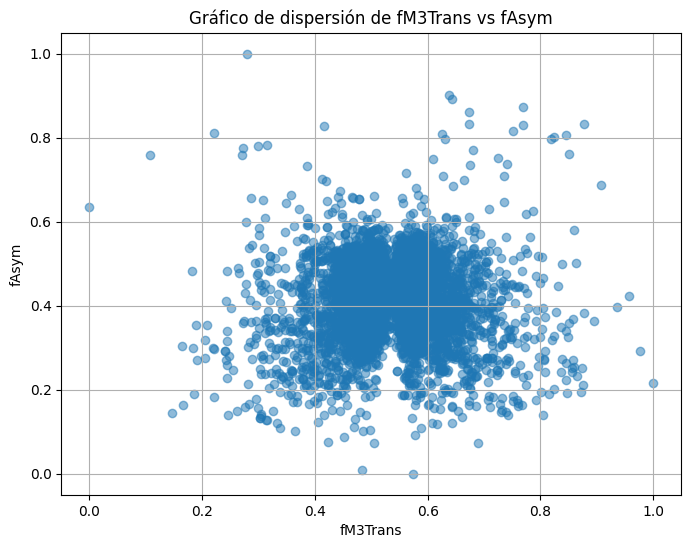

In [ ]:
feature1, feature2 = last_correlation_pairs.index[0]
feature1_data = normalized_df[feature1]
feature2_data = normalized_df[feature2]

plt.figure(figsize=(8,6))
plt.scatter(feature1_data, feature2_data, alpha=0.5)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title(f'Gráfico de dispersión de {feature1} vs {feature2}')
plt.grid(True)
plt.show()

Comparar graficos:

# Clasificación usando naive Bayes e histogramas

Se pide programar, entrenar y calibrar un clasificador naive Bayes para determinar en forma probabilística
si un candidato corresponde a la clase positiva (hadrón) o a la negativa (no-hadrón). La regla de decisión
del mencionado clasificador está dada por:
$$
\frac{P(\textit{características|positiva})}{P(\textit{caracrísticas|negativa})} \geq \Theta
$$
El umbral $\Theta$ depende de los costos asociados a cada decisión ($c_{\textit{positiva}}$ y $c_{\textit{negativa}}$) y de las probabilidades a priori:
$$
\Theta=\frac{c_{\text{positiva}}P(\text{negativa})}{c_{\text{negativa}}P(\text{positiva})}
$$
En este caso concreto, las distribuciones de probabilidad condicional, i.e. las verosimilitudes, de ambos conjuntos no se tienen, por lo que deberá estimarlas utilizando histogramas normalizados.

## Parte 10
Dividir la base de datos en 2 conjuntos representativos: entrenamiento (80%) y prueba (20%).
Compruebe la representatividad de estos, verificando si la proporción de ambas clases en cada
conjunto se mantiene cercana a la proporción del conjunto completo. Se recomienda usar la función
train_test_split() para hacer la división, usando un random_state fijo.

In [ ]:
X = normalized_df.drop('class', axis=1)
y = normalized_df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=3)
original_proportion = [round(len(gamma_df)/len(magic04_df), 4), round(len(hadron_df)/len(magic04_df), 4)]
train_proportion = [round((y_train==0).sum()/len(y_train), 4), round((y_train==1).sum()/len(y_train), 4)]
test_proportion = [round((y_test==0).sum()/len(y_test), 4), round((y_test==1).sum()/len(y_test), 4)]
print(original_proportion, train_proportion, test_proportion)

[0.6484, 0.3516] [0.6484, 0.3516] [0.6483, 0.3517]


## Parte 11
Implemente un clasificador naive Bayes que use histogramas para representar las verosimilitudes.

In [ ]:
bins = int(3 * np.sqrt(len(X_test)))

def train_naive_bayes(X, y, bins=bins):
  classes = [0, 1]
  assert len(classes) == 2
  class_priors = {}
  feature_bins = {}
  for cls in classes:
      cls_samples = X[y == cls]
      class_priors[cls] = len(cls_samples)/len(y)
      feature_bins[cls] = []
      for col in X.columns:
          hist, bin_edges = np.histogram(cls_samples[col], bins=bins, density=True)
          hist_normalized = hist / sum(hist)
          feature_bins[cls].append((hist_normalized, bin_edges))

  return class_priors, feature_bins

def find_bin_index(bin_edges, value):
  for i in range(len(bin_edges) - 1):
    if bin_edges[i] <= value < bin_edges[i + 1]:
      return i
  return -1

def calculate_likelihood(instance, feature_bins, epsilon=1e-9):
    likelihood = 1
    for index, hist_and_edges in enumerate(feature_bins):
        hist, bin_edges = hist_and_edges
        bin_index = find_bin_index(bin_edges, instance[index])
        if bin_index >= 0 and bin_index < len(hist) - 1:
            left_bin = hist[bin_index]
            right_bin = hist[bin_index + 1]
            bin_width = bin_edges[1] - bin_edges[0]
            interpolation_factor = (instance[index] - bin_edges[bin_index]) / bin_width
            left_bin_smoothed = left_bin + epsilon
            right_bin_smoothed = right_bin + epsilon
            likelihood *= left_bin_smoothed + (right_bin_smoothed - left_bin_smoothed) * interpolation_factor
        else:
            likelihood *= epsilon

    return likelihood


def predict_naive_bayes(X, class_priors, feature_bins, theta):
    predictions = []
    for _, instance in X.iterrows():
      likelihood_0 = calculate_likelihood(instance, feature_bins[0])
      likelihood_1 = calculate_likelihood(instance, feature_bins[1])
      prob_ratio = (class_priors[1] * likelihood_1) / (class_priors[0] * likelihood_0)
      predicted_class = 1 if prob_ratio >= theta else 0
      predictions.append(predicted_class)

    return predictions

def calculate_theta(c_pos, p_pos, c_neg, p_neg):
  return (c_pos * p_neg) / (c_neg * p_pos)

## Parte 12
Utilice la aproximación Naive Bayes y calcule los histogramas de cada clase a partir de las muestras
del conjunto de entrenamiento. Elija un número de bins que le parezca apropiado, y use el mismo
número de bins para todas las características. Se recomienda normalizar los histogramas.

In [ ]:
def calculate_class_histograms(X, y, bins=bins):
  classes = [0, 1]
  class_histograms = {}
  for cls in classes:
    cls_samples = X[y == cls]
    class_histograms[cls] = []
    for col in X.columns:
      hist, bin_edges = np.histogram(cls_samples[col], bins=bins, density=True)
      hist_normalized = hist / sum(hist)
      class_histograms[cls].append((hist_normalized, bin_edges))

  return class_histograms

class_histograms = calculate_class_histograms(X_train, y_train)

## Parte 13
Grafique los histogramas usando plt.bar(), con alpha = 0.5. En cada gráfico se debe superponer
el histograma de una característica para la clase positiva y el histograma para la clase negativa.

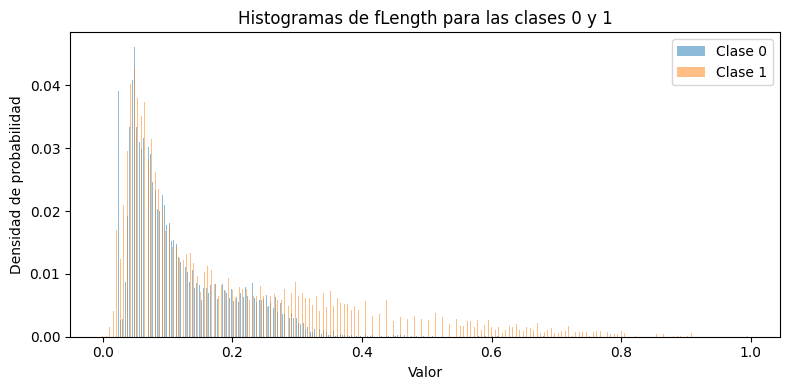

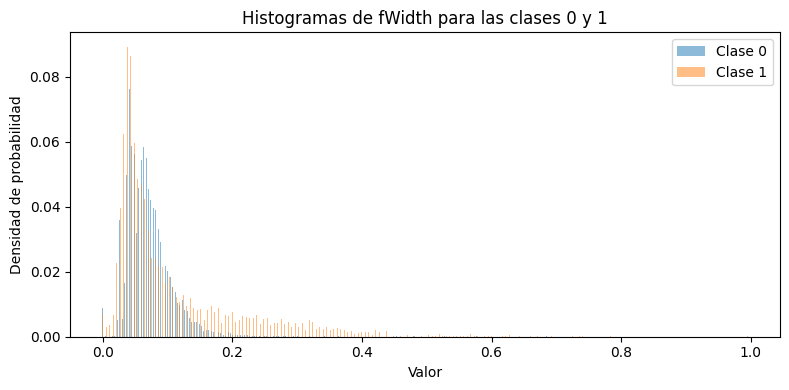

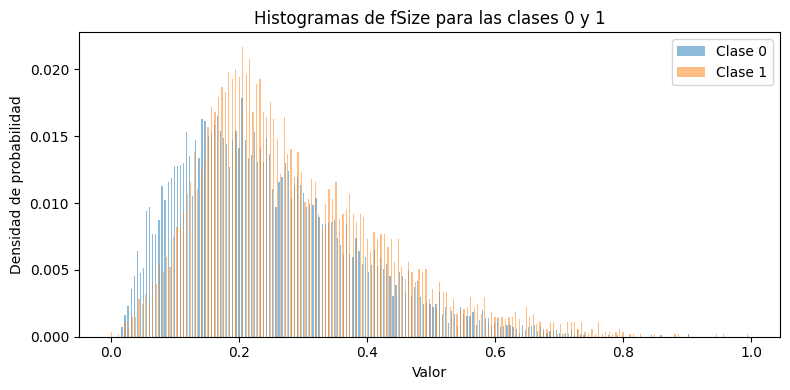

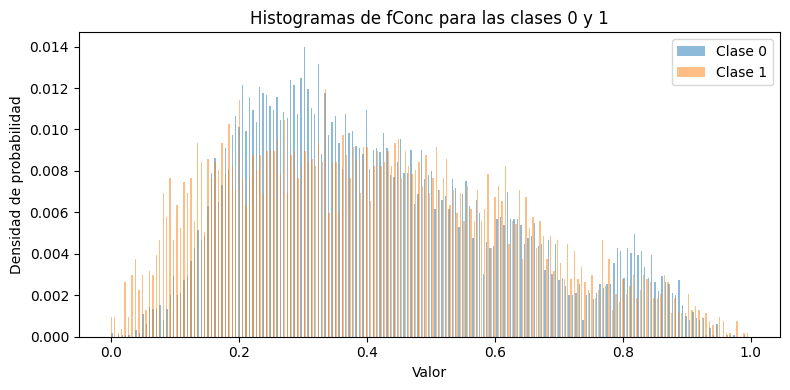

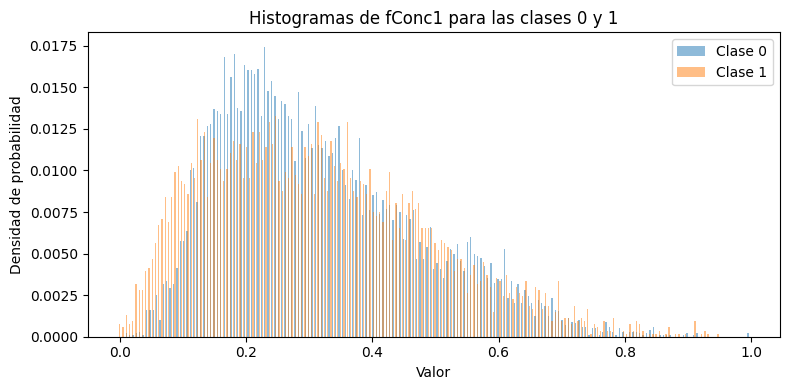

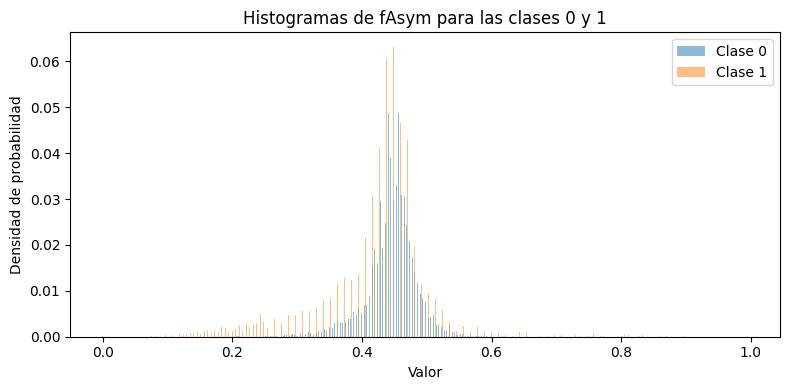

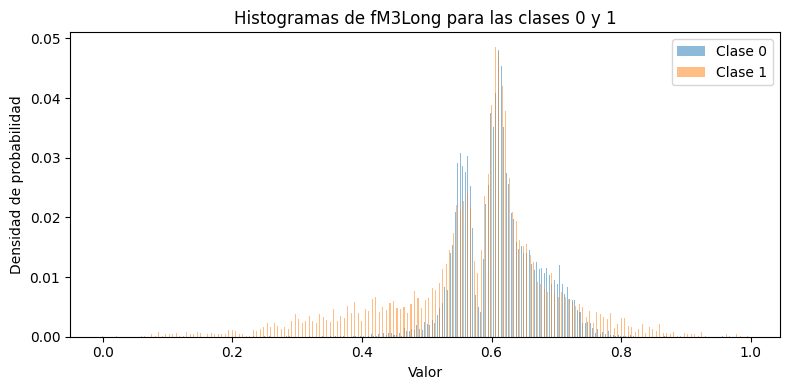

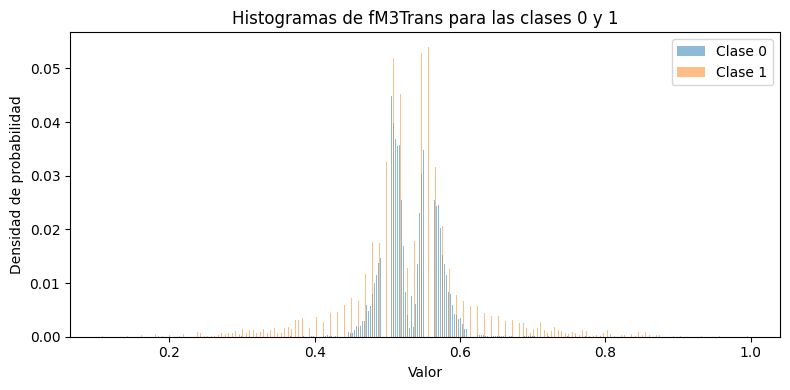

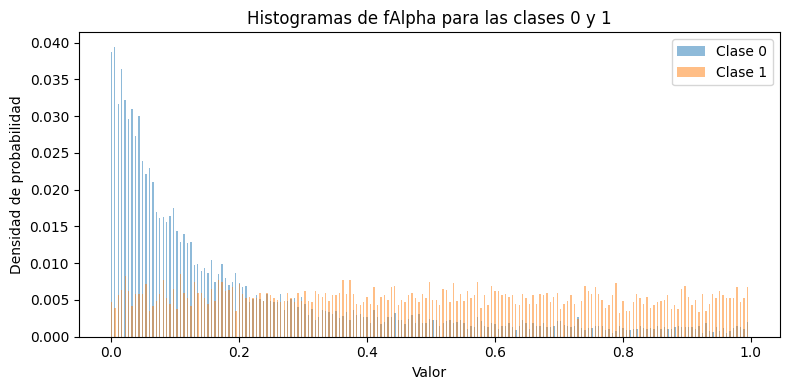

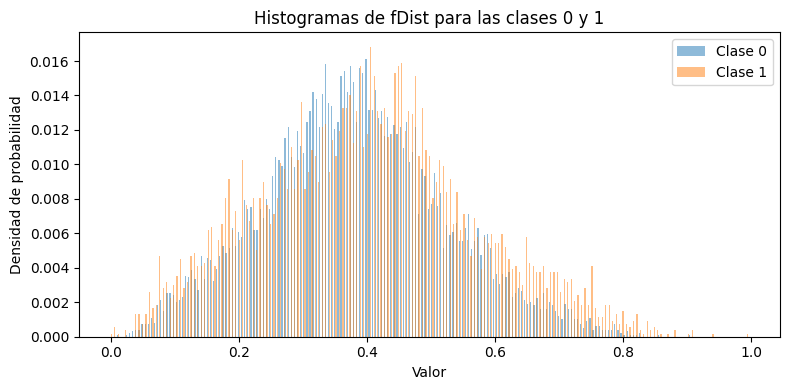

In [ ]:
classes = [0, 1]
num_features = len(X_train.columns)
num_classes = len(classes)
for i, col in enumerate(X_train.columns):
    hist0, bin_edges0 = class_histograms[classes[0]][i]
    hist1, bin_edges1 = class_histograms[classes[1]][i]
    bar_width = (bin_edges0[1] - bin_edges0[0]) * 0.4
    fig, axs = plt.subplots(figsize=(8, 4))
    axs.bar(bin_edges0[:-1], hist0, width=bar_width, alpha=0.5, label=f'Clase {classes[0]}')
    axs.bar(bin_edges1[:-1], hist1, width=bar_width, alpha=0.5, label=f'Clase {classes[1]}')
    axs.set_xlabel('Valor')
    axs.set_ylabel('Densidad de probabilidad')
    axs.set_title(f'Histogramas de {col} para las clases {classes[0]} y {classes[1]}')
    axs.legend()
    plt.tight_layout()
    plt.show()

## Parte 14
Probar el clasificador: utilizando distintos valores de Θ, clasificar el conjunto de prueba y calcular la
Tasa de Verdaderos Positivos y Tasa de Falsos Positivos, para luego generar la curva ROC (TVP vs
TFP) para el conjunto de prueba. Recuerde que Θ puede tomar valores entre 0 e ∞, pero no todo el
rango entrega información importante.

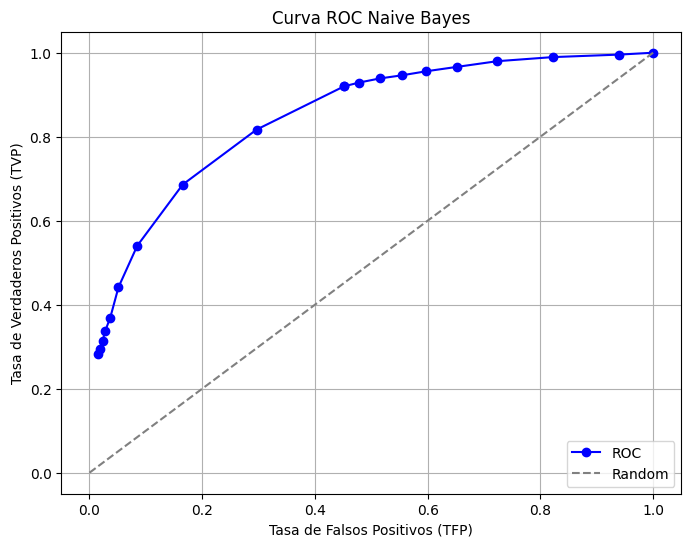

In [ ]:
def confusion_matrix(y_true, y_predict):
  matrix = [[0, 0], [0, 0]]
  for true, pred in zip(y_true, y_predict):
    matrix[true][pred] += 1

  return matrix[0][0], matrix[0][1], matrix[1][0], matrix[1][1]

def calculate_TVP_and_TFP(y, y_pred):
  tn, fp, fn, tp = confusion_matrix(y, y_pred)
  TVP = tp / (tp + fn) if (tp + fn) != 0 else 0
  TFP = fp / (fp + tn) if (fp + tn) != 0 else 0

  return TVP, TFP

class_priors, feature_bins = train_naive_bayes(X_train, y_train)
thresholds = np.concatenate((np.linspace(0, 1, 10), np.logspace(np.log10(1), np.log10(1000), 10)))
tvp_points = []
tfp_points = []
predictions_list = []
for theta in thresholds:
  predictions = predict_naive_bayes(X_test, class_priors, feature_bins, theta)
  tvp, tfp = calculate_TVP_and_TFP(y_test.values, predictions)
  tvp_points.append(tvp)
  tfp_points.append(tfp)
plt.figure(figsize=(8, 6))
plt.plot(tfp_points, tvp_points, marker='o', color='blue', label='ROC')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('Tasa de Falsos Positivos (TFP)')
plt.ylabel('Tasa de Verdaderos Positivos (TVP)')
plt.title('Curva ROC Naive Bayes')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Parte 15
Genere la curva precisión-recall para el conjunto de prueba.

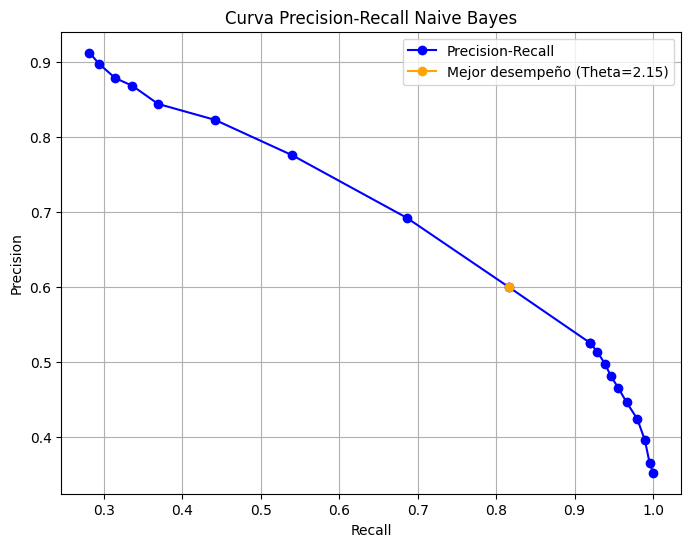

In [ ]:
def calculate_precision_and_recall(y, y_pred):
  tn, fp, fn, tp = confusion_matrix(y, y_pred)
  precision = tp / (tp + fp) if tp + fp != 0 else 0
  recall = tp / (tp + fn) if tp + fn != 0 else 0
  return precision, recall

class_priors, feature_bins = train_naive_bayes(X_train, y_train)
thresholds = np.concatenate((np.linspace(0, 1, 10), np.logspace(np.log10(1), np.log10(1000), 10)))
precision_points = []
recall_points = []
f1_scores = []
for theta in thresholds:
  predictions = predict_naive_bayes(X_test, class_priors, feature_bins, theta)
  precision, recall = calculate_precision_and_recall(y_test.values, predictions)
  precision_points.append(precision)
  recall_points.append(recall)
  f1_scores.append(2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0)
best_performance_index = np.argmax(np.array(f1_scores))
best_precision = precision_points[best_performance_index]
best_recall = recall_points[best_performance_index]
best_threshold = thresholds[best_performance_index]
plt.figure(figsize=(8, 6))
plt.plot(recall_points, precision_points, marker='o', color='blue', label='Precision-Recall')
plt.plot(best_recall, best_precision, marker='o', color='orange', label=f'Mejor desempeño (Theta={best_threshold:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall Naive Bayes')
plt.grid(True)
plt.legend()
plt.show()

# Clasificación usando gaussianas multivariantes
En esta sección se pide programar un clasificador basado en gaussianas multivariantes, el cual no usa la
aproximación naive Bayes.

## Parte 16
Entrenar un modelo gaussiano multidimensional para cada clase, calculando la media y covarianza, a
partir del conjunto de entrenamiento. Puede basarse en las funciones np.mean( ) y np.cov( ) de
numpy.

In [ ]:
def train_gaussian(X, y):
  classes = [0, 1]
  class_gaussians = {}
  for cls in classes:
    cls_samples = X[y == cls]
    mean = np.mean(cls_samples, axis=0)
    covariance = np.cov(cls_samples, rowvar=False)
    class_gaussians[cls] = {'mean': mean, 'covariance': covariance}

  return class_gaussians

class_gaussians = train_gaussian(X_train, y_train)
for cls, gaussian in class_gaussians.items():
  print(f'Clase {cls}:')
  print(f'\n Media: {gaussian["mean"]}')
  print(f'\n Covarianza: {gaussian["covariance"]}')

Clase 0:

 Media: fLength     0.119331
fWidth      0.072558
fSize       0.249018
fConc       0.420498
fConc1      0.317963
fAsym       0.446400
fM3Long     0.613295
fM3Trans    0.534345
fAlpha      0.207543
fDist       0.383088
dtype: float64

 Covarianza: [[ 6.26400444e-03  1.94804573e-03  8.25757777e-03 -1.13477844e-02
  -8.44527492e-03 -3.53377945e-04  2.54265382e-03  2.88218529e-05
  -8.32608753e-03  6.73070402e-03]
 [ 1.94804573e-03  1.24666541e-03  4.09996436e-03 -5.39847433e-03
  -4.03476116e-03 -3.84891773e-06  8.82100946e-04  4.70211184e-05
  -2.47559640e-03  1.96192447e-03]
 [ 8.25757777e-03  4.09996436e-03  1.85689345e-02 -2.36866080e-02
  -1.76198909e-02  1.78410386e-04  4.39510798e-03  8.68362112e-05
  -1.48658217e-02  8.92339506e-03]
 [-1.13477844e-02 -5.39847433e-03 -2.36866080e-02  4.05539052e-02
   3.08923210e-02 -2.93328869e-04 -5.40159075e-03 -1.00431454e-04
   2.30892042e-02 -1.06259623e-02]
 [-8.44527492e-03 -4.03476116e-03 -1.76198909e-02  3.08923210e-02
   2.4544

## Parte 17
Implemente el clasificador

In [ ]:
def multivariate_gaussian_pdf(x, mean, covariance):
  n = len(mean)
  mean_arr = np.array(mean)
  diff = x - mean_arr
  coef = 1 / ((2 * np.pi) ** (n/2) * np.sqrt(np.linalg.det(covariance)))
  exponent = -0.5 * (diff @ np.linalg.inv(covariance)) @ diff.T
  return coef * np.exp(exponent)

def predict_gaussian(X, class_gaussians, threshold):
  epsilon = 1e-9
  predictions = []
  for instance in X.values:
      likelihood_ratios = []
      for cls, gaussian in class_gaussians.items():
          mean = gaussian['mean']
          covariance = gaussian['covariance']
          probability = multivariate_gaussian_pdf(instance, mean, covariance)
          likelihood_ratios.append(probability)
      probability_ratio = likelihood_ratios[1] / (likelihood_ratios[0] + epsilon)
      predicted_class = 1 if probability_ratio >= threshold else 0
      predictions.append(predicted_class)

  return predictions

## Parte 18
Probar el clasificador: utilizando distintos valores de Θ, clasificar el conjunto de prueba y calcular la
Tasa de Verdaderos Positivos y Tasa de Falsos Positivos para luego generar la curva ROC (TVP vs
TFP) para el conjunto de prueba.

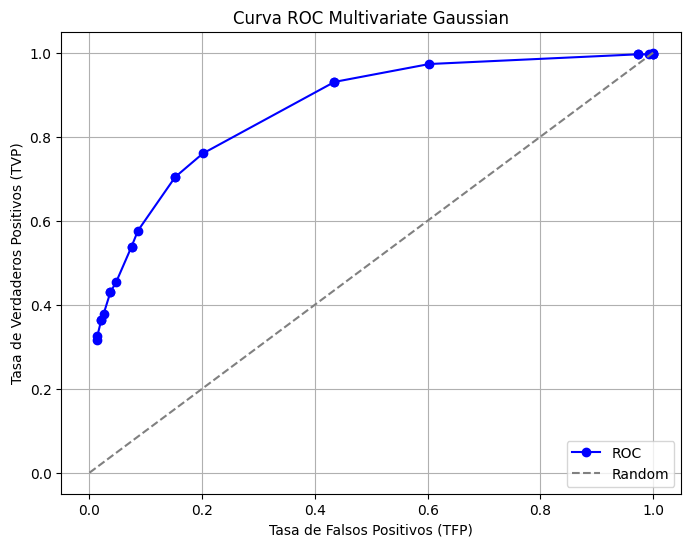

In [ ]:
class_gaussians = train_gaussian(X_train, y_train)
thresholds = np.concatenate([np.linspace(0, 0.0001, 3), np.linspace(0.0001, 0.001, 3), np.linspace(0.001, 0.01, 3), np.linspace(0.01, 0.1, 3), np.linspace(0.1, 1, 3), np.linspace(1, 10, 3), np.linspace(10, 100, 3), np.linspace(100, 1000, 3)])
tvp_points = []
tfp_points = []
for theta in thresholds:
  predictions = predict_gaussian(X_test, class_gaussians, theta)
  tvp, tfp = calculate_TVP_and_TFP(y_test.values, predictions)
  tvp_points.append(tvp)
  tfp_points.append(tfp)
plt.figure(figsize=(8, 6))
plt.plot(tfp_points, tvp_points, marker='o', color='blue', label='ROC')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('Tasa de Falsos Positivos (TFP)')
plt.ylabel('Tasa de Verdaderos Positivos (TVP)')
plt.title('Curva ROC Multivariate Gaussian')
plt.grid(True)
plt.legend(loc='lower right')
plt.show()

## Parte 19
Genere la curva precisión-recall para el conjunto de prueba.

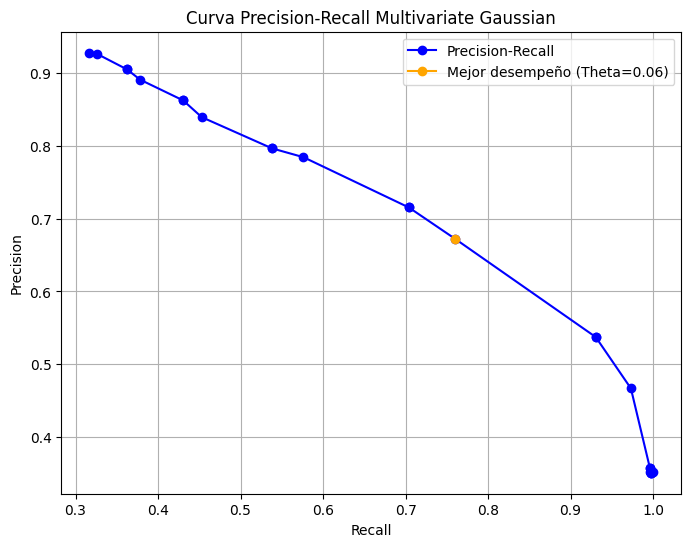

In [ ]:
class_gaussians = train_gaussian(X_train, y_train)
thresholds = np.concatenate([np.linspace(0, 0.0001, 3), np.linspace(0.0001, 0.001, 3), np.linspace(0.001, 0.01, 3), np.linspace(0.01, 0.1, 3), np.linspace(0.1, 1, 3), np.linspace(1, 10, 3), np.linspace(10, 100, 3), np.linspace(100, 1000, 3)])
precision_points = []
recall_points = []
f1_scores = []
for threshold in thresholds:
  predictions = predict_gaussian(X_test, class_gaussians, threshold)
  precision, recall = calculate_precision_and_recall(y_test.values, predictions)
  precision_points.append(precision)
  recall_points.append(recall)
  f1_scores.append(2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0)
best_performance_index = np.argmax(np.array(f1_scores))
best_precision = precision_points[best_performance_index]
best_recall = recall_points[best_performance_index]
best_threshold = thresholds[best_performance_index]
plt.figure(figsize=(8, 6))
plt.plot(recall_points, precision_points, marker='o', color='blue', label='Precision-Recall')
plt.plot(best_recall, best_precision, marker='o', color='orange', label=f'Mejor desempeño (Theta={best_threshold:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall Multivariate Gaussian')
plt.grid(True)
plt.legend()
plt.show()

# Comparación de resultados

## Parte 20
Grafique las curvas ROC de los clasificadores entrenados en un único gráfico. Analice las métricas
obtenidas por ambos clasificadores.

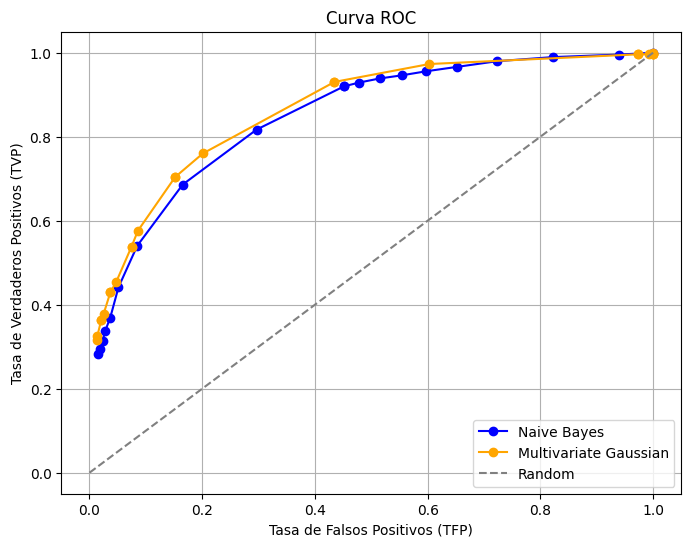

In [ ]:
class_priors, feature_bins = train_naive_bayes(X_train, y_train)
class_gaussians = train_gaussian(X_train, y_train)
thresholds = (np.concatenate((np.linspace(0, 1, 10), np.logspace(np.log10(1), np.log10(1000), 10))), np.concatenate([np.linspace(0, 0.0001, 3), np.linspace(0.0001, 0.001, 3), np.linspace(0.001, 0.01, 3), np.linspace(0.01, 0.1, 3), np.linspace(0.1, 1, 3), np.linspace(1, 10, 3), np.linspace(10, 100, 3), np.linspace(100, 1000, 3)]))
tvp_points = {'NaiveBayes': [], 'MultivariateGaussian': []}
tfp_points = {'NaiveBayes': [], 'MultivariateGaussian': []}
for threshold in thresholds[0]:
  predictions = predict_naive_bayes(X_test, class_priors, feature_bins, threshold)
  tvp, tfp = calculate_TVP_and_TFP(y_test.values, predictions)
  tvp_points['NaiveBayes'].append(tvp)
  tfp_points['NaiveBayes'].append(tfp)
for threshold in thresholds[1]:
  predictions = predict_gaussian(X_test, class_gaussians, threshold)
  tvp, tfp = calculate_TVP_and_TFP(y_test.values, predictions)
  tvp_points['MultivariateGaussian'].append(tvp)
  tfp_points['MultivariateGaussian'].append(tfp)
plt.figure(figsize=(8, 6))
plt.plot(tfp_points['NaiveBayes'], tvp_points['NaiveBayes'], marker='o', color='blue', label='Naive Bayes')
plt.plot(tfp_points['MultivariateGaussian'], tvp_points['MultivariateGaussian'], marker='o', color='orange', label='Multivariate Gaussian')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('Tasa de Falsos Positivos (TFP)')
plt.ylabel('Tasa de Verdaderos Positivos (TVP)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Parte 21
Grafique las curvas precisión-recall de los clasificadores entrenados en un único gráfico. Analice las
métricas obtenidas por ambos clasificadores.

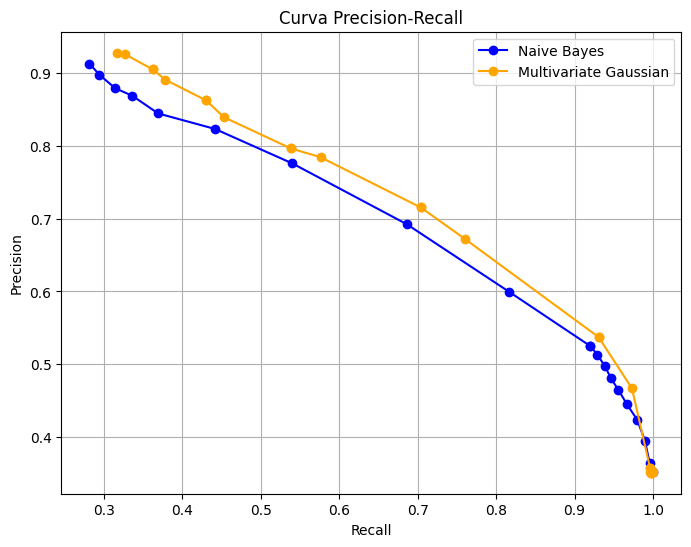

In [ ]:
class_priors, feature_bins = train_naive_bayes(X_train, y_train)
class_gaussians = train_gaussian(X_train, y_train)
thresholds = (np.concatenate((np.linspace(0, 1, 10), np.logspace(np.log10(1), np.log10(1000), 10))), np.concatenate([np.linspace(0, 0.0001, 3), np.linspace(0.0001, 0.001, 3), np.linspace(0.001, 0.01, 3), np.linspace(0.01, 0.1, 3), np.linspace(0.1, 1, 3), np.linspace(1, 10, 3), np.linspace(10, 100, 3), np.linspace(100, 1000, 3)]))
precision_points = {'NaiveBayes': [], 'MultivariateGaussian': []}
recall_points = {'NaiveBayes': [], 'MultivariateGaussian': []}
for threshold in thresholds[0]:
  predictions = predict_naive_bayes(X_test, class_priors, feature_bins, threshold)
  precision, recall = calculate_precision_and_recall(y_test.values, predictions)
  precision_points['NaiveBayes'].append(precision)
  recall_points['NaiveBayes'].append(recall)
for threshold in thresholds[1]:
  predictions = predict_gaussian(X_test, class_gaussians, threshold)
  precision, recall = calculate_precision_and_recall(y_test.values, predictions)
  precision_points['MultivariateGaussian'].append(precision)
  recall_points['MultivariateGaussian'].append(recall)
plt.figure(figsize=(8, 6))
plt.plot(recall_points['NaiveBayes'], precision_points['NaiveBayes'], marker='o', color='blue', label='Naive Bayes')
plt.plot(recall_points['MultivariateGaussian'], precision_points['MultivariateGaussian'], marker='o', color='orange', label='Multivariate Gaussian')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

## Parte 22
Compare los tiempos requeridos para entrenar ambos clasificadores.

In [ ]:
# Naive Bayes Histogram
start_NB = time.time()
class_priors, feature_bins = train_naive_bayes(X_train, y_train)
end_NB = time.time()

# Multivariate Gaussian
start_MG = time.time()
class_gaussians = train_gaussian(X_train, y_train)
end_MG = time.time()

# Calculo
execution_time_NB = end_NB - start_NB
execution_time_MG = end_MG - start_MG
# Impresión de los tiempos
print(f'Tiempo de ejecución de la clasificación mediante Naive Bayes: {execution_time_NB} segundos')
print(f'Tiempo de ejecución de la clasificación mediante Multivariate Gaussian: {execution_time_MG} segundos')

# Comparar los tiempos de ejecución
if execution_time_NB < execution_time_MG:
    print('El metodo Naive Bayes fue más rapido.')
elif execution_time_NB > execution_time_MG:
    print('El metodo Multivariate Gaussian fue más rapido.')
else:
    print('Ambos metodos tardan lo mismo.')

Tiempo de ejecución de la clasificación mediante Naive Bayes: 0.05498480796813965 segundos
Tiempo de ejecución de la clasificación mediante Multivariate Gaussian: 0.011124849319458008 segundos
El metodo Multivariate Gaussian fue más rapido.
